# Task 1: Refining a Pre-trained Text-to-Image Model with LoRA — Oxford-102 Flowers

**Internship objective:** Use a custom dataset to refine a pre-trained text-to-image model so it produces domain-specific visuals.

This notebook adapts **Stable Diffusion v1.5** to the same **Oxford-102 Flowers** domain used throughout the internship. Instead of updating the entire diffusion model, it uses **LoRA (Low-Rank Adaptation)**, which keeps the original model weights frozen and trains a small set of adapter parameters.

### Experiment design
- **Base model:** `stable-diffusion-v1-5/stable-diffusion-v1-5`
- **Dataset:** Oxford-102 Flowers
- **Domain subset:** the same five representative categories used in Tasks 2 and 5
- **Categories:** daffodil, sunflower, rose, lotus, hibiscus
- **Captions:** natural text prompts derived from the flower category
- **Fine-tuning method:** LoRA on the Stable Diffusion UNet
- **Evaluation:** compare the base model and LoRA-refined model using identical prompts and seeds

> **Important:** Use a Google Colab GPU runtime. A T4 GPU is suitable for this compact LoRA experiment, although training time depends on the available runtime.


## 1. Check GPU

In Colab choose **Runtime → Change runtime type → T4 GPU** before continuing.


In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU not detected. In Colab select Runtime → Change runtime type → T4 GPU."
    )

print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


## 2. Install Hugging Face Diffusers training tools

The official Diffusers repository contains the maintained text-to-image LoRA training script. This notebook clones that repository and installs the dependencies required by the script.


In [2]:
# Clean installation for Google Colab
!pip uninstall -y diffusers -q

!pip install -q -U \
    diffusers \
    transformers \
    accelerate \
    peft \
    datasets \
    safetensors \
    huggingface_hub \
    sentencepiece

print("Installation complete.")
print("IMPORTANT: Restart the runtime before continuing.")

Installation complete.
IMPORTANT: Restart the runtime before continuing.


## 3. Imports and reproducibility


In [3]:
import os
import json
import random
import shutil
import tarfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.io import loadmat

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

ROOT = Path("/content/task1_oxford102_lora")
ROOT.mkdir(parents=True, exist_ok=True)

print("Working directory:", ROOT)


Working directory: /content/task1_oxford102_lora


## 4. Download the same Oxford-102 Flowers dataset

This uses the Oxford Visual Geometry Group image archive and class-label file, matching the dataset used in the earlier internship tasks.


In [4]:
DATA_DIR = ROOT / "oxford102"
DATA_DIR.mkdir(exist_ok=True)

IMAGES_TGZ = DATA_DIR / "102flowers.tgz"
LABELS_MAT = DATA_DIR / "imagelabels.mat"
JPG_DIR = DATA_DIR / "jpg"

if not IMAGES_TGZ.exists():
    urllib.request.urlretrieve(
        "https://www.robots.ox.ac.uk/~vgg/data/flowers/102/102flowers.tgz",
        IMAGES_TGZ
    )

if not LABELS_MAT.exists():
    urllib.request.urlretrieve(
        "https://www.robots.ox.ac.uk/~vgg/data/flowers/102/imagelabels.mat",
        LABELS_MAT
    )

if not JPG_DIR.exists():
    with tarfile.open(IMAGES_TGZ, "r:gz") as tar:
        tar.extractall(DATA_DIR)

labels = loadmat(LABELS_MAT)["labels"][0].astype(int)

print("Images:", len(list(JPG_DIR.glob("*.jpg"))))
print("Labels:", len(labels))


Images: 8189
Labels: 8189


## 5. Flower class names and selected domain subset

We retain the same five categories used in the CGAN and Attention-CGAN experiments so all internship tasks remain part of one coherent Oxford-102 project.


In [5]:
FLOWER_CLASSES = [
    'pink primrose','hard-leaved pocket orchid','canterbury bells','sweet pea',
    'english marigold','tiger lily','moon orchid','bird of paradise','monkshood',
    'globe thistle','snapdragon',"colt's foot",'king protea','spear thistle',
    'yellow iris','globe-flower','purple coneflower','peruvian lily',
    'balloon flower','giant white arum lily','fire lily','pincushion flower',
    'fritillary','red ginger','grape hyacinth','corn poppy','prince of wales feathers',
    'stemless gentian','artichoke','sweet william','carnation','garden phlox',
    'love in the mist','mexican aster','alpine sea holly','ruby-lipped cattleya',
    'cape flower','great masterwort','siam tulip','lenten rose','barbeton daisy',
    'daffodil','sword lily','poinsettia','bolero deep blue','wallflower',
    'marigold','buttercup','oxeye daisy','common dandelion','petunia','wild pansy',
    'primula','sunflower','pelargonium','bishop of llandaff','gaura','geranium',
    'orange dahlia','pink-yellow dahlia?','cautleya spicata','japanese anemone',
    'black-eyed susan','silverbush','californian poppy','osteospermum',
    'spring crocus','bearded iris','windflower','tree poppy','gazania','azalea',
    'water lily','rose','thorn apple','morning glory','passion flower','lotus',
    'toad lily','anthurium','frangipani','clematis','hibiscus','columbine',
    'desert-rose','tree mallow','magnolia','cyclamen','watercress','canna lily',
    'hippeastrum','bee balm','ball moss','foxglove','bougainvillea','camellia',
    'mallow','mexican petunia','bromelia','blanket flower','trumpet creeper',
    'blackberry lily'
]

SELECTED_CLASSES = ["daffodil", "sunflower", "rose", "lotus", "hibiscus"]
selected_label_ids = {
    name: FLOWER_CLASSES.index(name) + 1
    for name in SELECTED_CLASSES
}

print(selected_label_ids)


{'daffodil': 42, 'sunflower': 54, 'rose': 74, 'lotus': 78, 'hibiscus': 83}


## 6. Build a compact custom fine-tuning dataset

A full 8,189-image diffusion fine-tuning run would be unnecessarily heavy for this internship demonstration. We therefore create a representative custom subset from the same Oxford-102 dataset.

For each selected flower category, up to **30 images** are used. Each image receives a simple natural-language caption such as:

`a detailed photo of a sunflower flower`

For class names that already contain the word *flower*, the caption function avoids duplicate wording.


In [6]:
MAX_IMAGES_PER_CLASS = 30
TRAIN_DIR = ROOT / "flower_lora_dataset"
TRAIN_DIR.mkdir(exist_ok=True)

def make_caption(class_name):
    if "flower" in class_name.lower():
        return f"a detailed photo of a {class_name}"
    return f"a detailed photo of a {class_name} flower"

records = []

for class_name in SELECTED_CLASSES:
    class_id = selected_label_ids[class_name]
    indices = np.where(labels == class_id)[0]
    rng = np.random.default_rng(SEED + class_id)
    rng.shuffle(indices)
    indices = indices[:MAX_IMAGES_PER_CLASS]

    for idx in indices:
        src = JPG_DIR / f"image_{idx+1:05d}.jpg"
        dst_name = f"{class_name.replace(' ', '_')}_{idx+1:05d}.jpg"
        dst = TRAIN_DIR / dst_name
        shutil.copy2(src, dst)

        records.append({
            "file_name": dst_name,
            "text": make_caption(class_name),
            "class_name": class_name
        })

train_df = pd.DataFrame(records)

print("Training images:", len(train_df))
display(train_df.head())
print("\nImages per class:")
display(train_df["class_name"].value_counts().sort_index())


Training images: 150


,file_name,text,class_name
0,daffodil_05733.jpg,a detailed photo of a daffodil flower,daffodil
1,daffodil_05713.jpg,a detailed photo of a daffodil flower,daffodil
2,daffodil_05721.jpg,a detailed photo of a daffodil flower,daffodil
3,daffodil_05701.jpg,a detailed photo of a daffodil flower,daffodil
4,daffodil_05708.jpg,a detailed photo of a daffodil flower,daffodil



Images per class:


,count
class_name,
daffodil,30
hibiscus,30
lotus,30
rose,30
sunflower,30


## 7. Create Hugging Face ImageFolder metadata

Diffusers' text-to-image training script can read a local ImageFolder dataset when `metadata.jsonl` maps each image filename to its text caption.


In [7]:
metadata_path = TRAIN_DIR / "metadata.jsonl"

with open(metadata_path, "w", encoding="utf-8") as f:
    for row in train_df.to_dict("records"):
        item = {
            "file_name": row["file_name"],
            "text": row["text"]
        }
        f.write(json.dumps(item) + "\n")

print("Created:", metadata_path)
print("Dataset folder:", TRAIN_DIR)


Created: /content/task1_oxford102_lora/flower_lora_dataset/metadata.jsonl
Dataset folder: /content/task1_oxford102_lora/flower_lora_dataset


## 8. Preview the fine-tuning images and captions


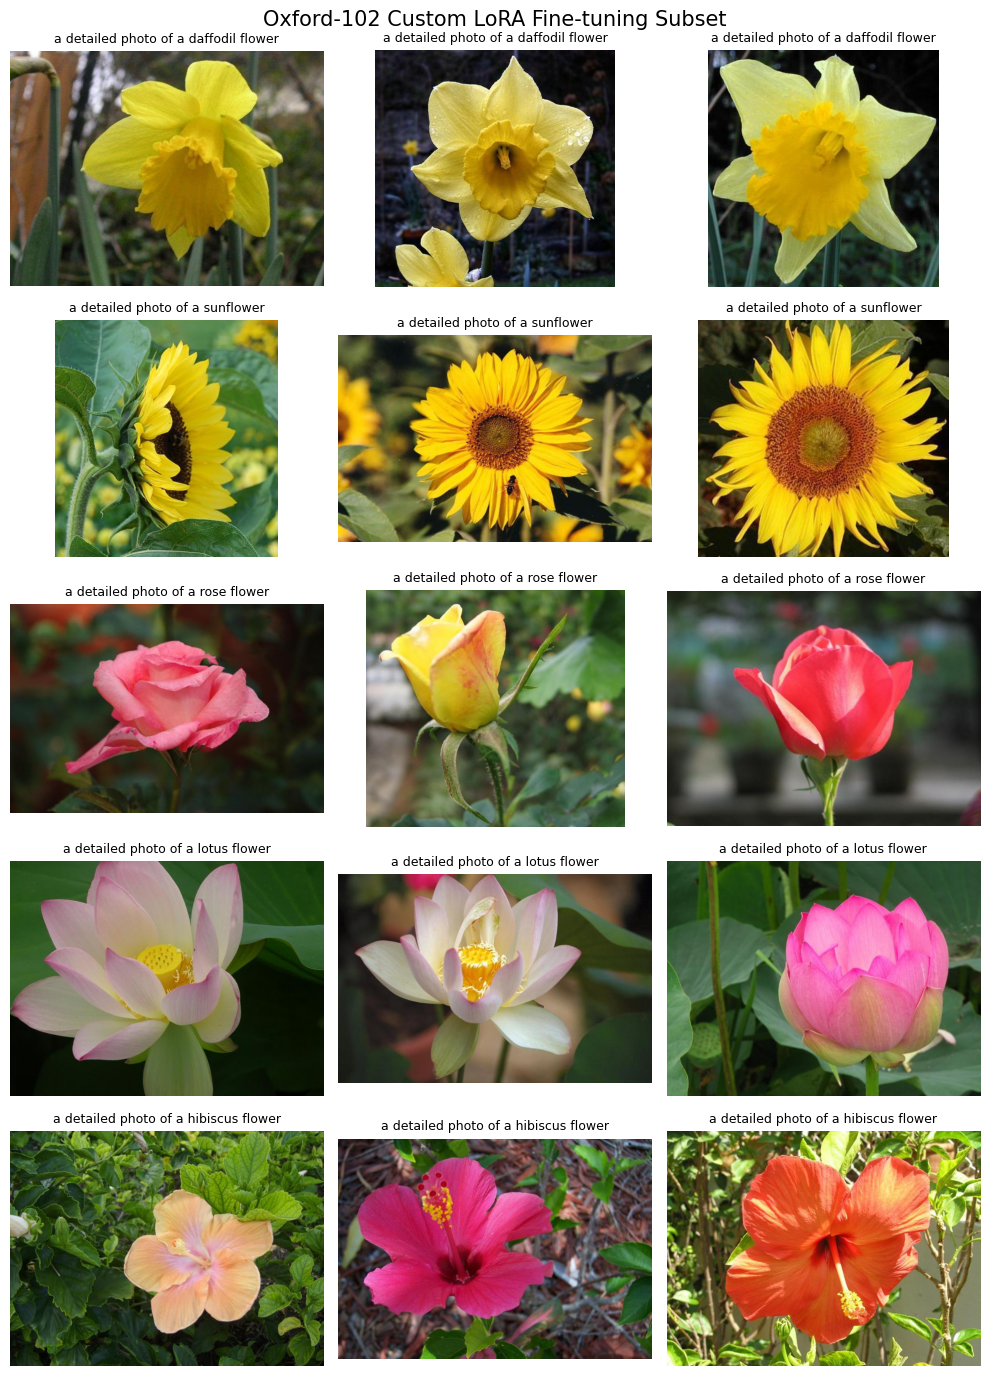

In [8]:
fig, axes = plt.subplots(len(SELECTED_CLASSES), 3, figsize=(10, 14))

for r, class_name in enumerate(SELECTED_CLASSES):
    examples = train_df[train_df["class_name"] == class_name].head(3)
    for c, (_, row) in enumerate(examples.iterrows()):
        img = Image.open(TRAIN_DIR / row["file_name"]).convert("RGB")
        axes[r, c].imshow(img)
        axes[r, c].axis("off")
        axes[r, c].set_title(row["text"], fontsize=9)

plt.suptitle("Oxford-102 Custom LoRA Fine-tuning Subset", fontsize=15)
plt.tight_layout()
plt.show()


## 9. Base Stable Diffusion model

We use Stable Diffusion v1.5 as the pre-trained text-to-image model. The LoRA adapter will refine its UNet for the Oxford flower domain while the large pre-trained weights remain frozen.

The model is downloaded from Hugging Face. If Hugging Face ever asks for authentication in your runtime, create a free account, accept any model terms shown on the model page, and use `huggingface_hub.login()`.


In [9]:
MODEL_NAME = "stable-diffusion-v1-5/stable-diffusion-v1-5"
OUTPUT_DIR = ROOT / "sd15_oxford102_lora"
OUTPUT_DIR.mkdir(exist_ok=True)

print("Base model:", MODEL_NAME)
print("LoRA output:", OUTPUT_DIR)


Base model: stable-diffusion-v1-5/stable-diffusion-v1-5
LoRA output: /content/task1_oxford102_lora/sd15_oxford102_lora


## 10. Generate baseline images before fine-tuning

These images provide a qualitative reference. Later we will generate the **same prompts with the same seeds** after loading the trained LoRA adapter.


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

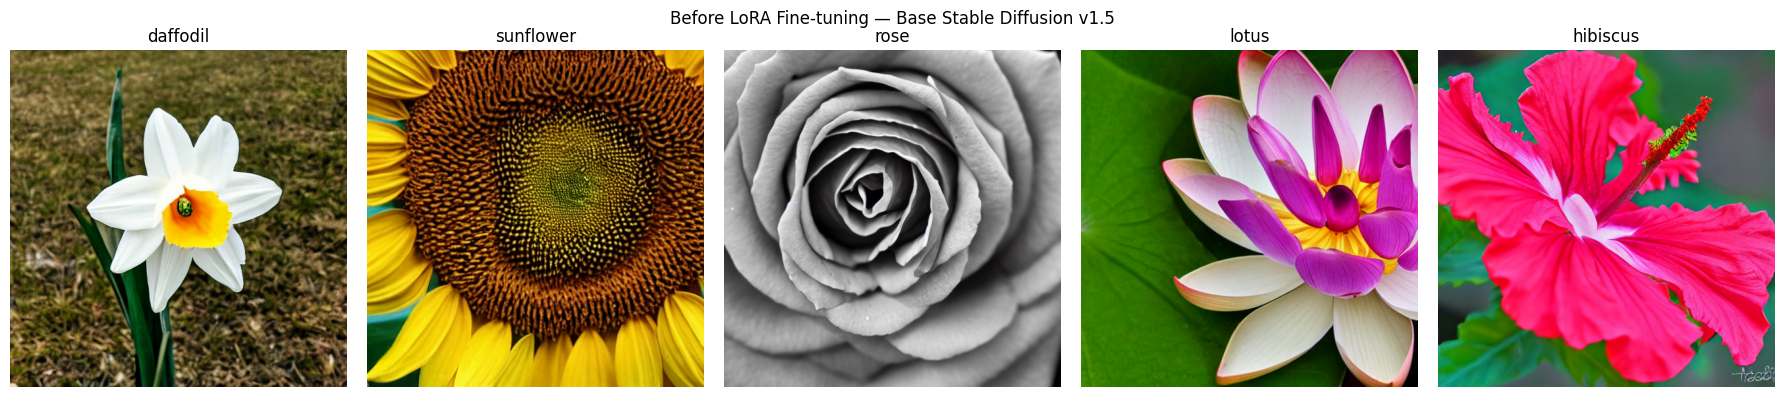

In [10]:
from diffusers import StableDiffusionPipeline

dtype = torch.float16
base_pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_NAME,
    torch_dtype=dtype,
    safety_checker=None
).to("cuda")

base_pipe.enable_attention_slicing()

EVAL_PROMPTS = [
    "a detailed photo of a daffodil flower",
    "a detailed photo of a sunflower flower",
    "a detailed photo of a rose flower",
    "a detailed photo of a lotus flower",
    "a detailed photo of a hibiscus flower"
]

BASELINE_DIR = ROOT / "baseline_images"
BASELINE_DIR.mkdir(exist_ok=True)

baseline_images = []

for i, prompt in enumerate(EVAL_PROMPTS):
    generator = torch.Generator(device="cuda").manual_seed(SEED + i)
    image = base_pipe(
        prompt,
        num_inference_steps=25,
        guidance_scale=7.5,
        generator=generator
    ).images[0]
    image.save(BASELINE_DIR / f"baseline_{i}_{SELECTED_CLASSES[i]}.png")
    baseline_images.append(image)

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for i, image in enumerate(baseline_images):
    axes[i].imshow(image)
    axes[i].set_title(SELECTED_CLASSES[i])
    axes[i].axis("off")
plt.suptitle("Before LoRA Fine-tuning — Base Stable Diffusion v1.5")
plt.tight_layout()
plt.show()

# Free GPU memory before training.
del base_pipe
torch.cuda.empty_cache()


## 11. Configure LoRA fine-tuning

This notebook uses the official Diffusers `train_text_to_image_lora.py` example.

The settings are deliberately compact for Colab:
- 512×512 training resolution
- batch size 1
- gradient accumulation
- mixed precision (`fp16`)
- gradient checkpointing
- LoRA rank 4
- 300 optimization steps

This is an internship-scale refinement experiment rather than an attempt to train a production-quality flower generator. If your runtime has more GPU time available, increasing `MAX_TRAIN_STEPS` can be explored as an additional experiment.


In [11]:
MAX_TRAIN_STEPS = 300
LORA_RANK = 4
LEARNING_RATE = 1e-4

print("Maximum training steps:", MAX_TRAIN_STEPS)
print("LoRA rank:", LORA_RANK)
print("Learning rate:", LEARNING_RATE)


Maximum training steps: 300
LoRA rank: 4
Learning rate: 0.0001


In [12]:
# Fix Diffusers version mismatch
%cd /content/diffusers

!pip uninstall -y diffusers
!pip install -e .

%cd /content

import diffusers
print("Diffusers version:", diffusers.__version__)
print("Diffusers location:", diffusers.__file__)

/content/diffusers
Found existing installation: diffusers 0.40.0
Uninstalling diffusers-0.40.0:
  Successfully uninstalled diffusers-0.40.0
Obtaining file:///content/diffusers
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for diffusers (pyproject.toml) ... done
  Created wheel for diffusers: filename=diffusers-0.41.0.dev0-0.editable-py3-none-any.whl size=11480 sha256=acc673511f8a3482e8e731bfda0c3b045275f8aa94cefd76eddde3e621334597
  Stored in directory: /tmp/pip-ephem-wheel-cache-hpa1pgiy/wheels/ce/09/f1/683b43f8a222a091c8294e229524928cfaa64c9af69cd211b8
Successfully built diffusers


/content
Diffusers version: 0.40.0
Diffusers location: /usr/local/lib/python3.13/dist-packages/diffusers/__init__.py


In [2]:
from pathlib import Path

# Restore all variables needed for LoRA training
ROOT = Path("/content/task1_oxford102_lora")

MODEL_NAME = "stable-diffusion-v1-5/stable-diffusion-v1-5"
TRAIN_DIR = ROOT / "flower_lora_dataset"
OUTPUT_DIR = ROOT / "sd15_oxford102_lora"

TRAIN_SCRIPT = "/content/diffusers/examples/text_to_image/train_text_to_image_lora.py"

SEED = 42
MAX_TRAIN_STEPS = 300
LORA_RANK = 4
LEARNING_RATE = 1e-4

print("MODEL_NAME:", MODEL_NAME)
print("TRAIN_DIR:", TRAIN_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)
print("TRAIN_SCRIPT:", TRAIN_SCRIPT)

print("\nTraining script exists:", Path(TRAIN_SCRIPT).exists())
print("Training dataset exists:", TRAIN_DIR.exists())

if TRAIN_DIR.exists():
    print("Training images:", len(list(TRAIN_DIR.glob("*.jpg"))))

MODEL_NAME: stable-diffusion-v1-5/stable-diffusion-v1-5
TRAIN_DIR: /content/task1_oxford102_lora/flower_lora_dataset
OUTPUT_DIR: /content/task1_oxford102_lora/sd15_oxford102_lora
TRAIN_SCRIPT: /content/diffusers/examples/text_to_image/train_text_to_image_lora.py

Training script exists: True
Training dataset exists: True
Training images: 150


In [7]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [1]:
import diffusers
import torch

print("Diffusers:", diffusers.__version__)
print("Diffusers location:", diffusers.__file__)

from diffusers import (
    AutoencoderKL,
    DDPMScheduler,
    DiffusionPipeline,
    StableDiffusionPipeline,
    UNet2DConditionModel,
)

print("✅ All Stable Diffusion training imports successful")

Diffusers: 0.41.0.dev0
Diffusers location: /content/diffusers/src/diffusers/__init__.py
✅ All Stable Diffusion training imports successful


In [2]:
from pathlib import Path

ROOT = Path("/content/task1_oxford102_lora")

MODEL_NAME = "stable-diffusion-v1-5/stable-diffusion-v1-5"
TRAIN_DIR = ROOT / "flower_lora_dataset"
OUTPUT_DIR = ROOT / "sd15_oxford102_lora"

TRAIN_SCRIPT = "/content/diffusers/examples/text_to_image/train_text_to_image_lora.py"

SEED = 42
MAX_TRAIN_STEPS = 300
LORA_RANK = 4
LEARNING_RATE = 1e-4

print("Training script exists:", Path(TRAIN_SCRIPT).exists())
print("Training dataset exists:", TRAIN_DIR.exists())
print("Training images:", len(list(TRAIN_DIR.glob("*.jpg"))))

Training script exists: True
Training dataset exists: True
Training images: 150


## 12. Run LoRA training

This is the longest cell in the notebook. Let it finish completely.

The command uses your local Oxford-102 subset as the training dataset and writes the LoRA adapter to the output directory.


In [4]:
!accelerate launch "$TRAIN_SCRIPT" \
  --pretrained_model_name_or_path="$MODEL_NAME" \
  --train_data_dir="$TRAIN_DIR" \
  --image_column="image" \
  --caption_column="text" \
  --resolution=512 \
  --center_crop \
  --random_flip \
  --train_batch_size=1 \
  --gradient_accumulation_steps=4 \
  --gradient_checkpointing \
  --mixed_precision="fp16" \
  --rank=$LORA_RANK \
  --learning_rate=$LEARNING_RATE \
  --lr_scheduler="constant" \
  --lr_warmup_steps=0 \
  --max_train_steps=$MAX_TRAIN_STEPS \
  --checkpointing_steps=100 \
  --seed=$SEED \
  --output_dir="$OUTPUT_DIR"

09/26/2026 08:26:14 - INFO - __main__ - [RANK 0] Distributed environment: DistributedType.NO
Num processes: 1
Process index: 0
Local process index: 0
Device: cuda

Mixed precision type: fp16

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
09/26/2026 08:26:14 - INFO - httpx - HTTP Request: HEAD https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5/resolve/main/scheduler/scheduler_config.json "HTTP/1.1 307 Temporary Redirect"
09/26/2026 08:26:14 - INFO - httpx - HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/stable-diffusion-v1-5/stable-diffusion-v1-5/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/scheduler%2Fscheduler_config.json?%2Fstable-diffusion-v1-5%2Fstable-diffusion-v1-5%2Fresolve%2Fmain%2Fscheduler%2Fscheduler_config.json=&etag=%2282d05b0e68

## 13. Verify the trained LoRA files


In [6]:
print("Files in LoRA output directory:")
for p in sorted(OUTPUT_DIR.rglob("*")):
    if p.is_file():
        print("-", p.relative_to(OUTPUT_DIR))

weight_files = list(OUTPUT_DIR.glob("*.safetensors"))
if not weight_files:
    raise FileNotFoundError(
        "No LoRA .safetensors file was found. Check the training cell for errors."
    )

print("\nLoRA weights found:", [p.name for p in weight_files])


Files in LoRA output directory:
- checkpoint-100/optimizer.bin
- checkpoint-100/pytorch_lora_weights.safetensors
- checkpoint-100/random_states_0.pkl
- checkpoint-100/scaler.pt
- checkpoint-100/scheduler.bin
- checkpoint-200/optimizer.bin
- checkpoint-200/pytorch_lora_weights.safetensors
- checkpoint-200/random_states_0.pkl
- checkpoint-200/scaler.pt
- checkpoint-200/scheduler.bin
- checkpoint-300/optimizer.bin
- checkpoint-300/pytorch_lora_weights.safetensors
- checkpoint-300/random_states_0.pkl
- checkpoint-300/scaler.pt
- checkpoint-300/scheduler.bin
- logs/text2image-fine-tune/1790411193.3285208/events.out.tfevents.1790411193.f34896e63b18.13586.1
- logs/text2image-fine-tune/1790411193.330355/hparams.yml
- logs/text2image-fine-tune/events.out.tfevents.1790411193.f34896e63b18.13586.0
- pytorch_lora_weights.safetensors

LoRA weights found: ['pytorch_lora_weights.safetensors']


In [8]:
EVAL_PROMPTS = [
    "a detailed photo of a daffodil flower",
    "a detailed photo of a sunflower flower",
    "a detailed photo of a rose flower",
    "a detailed photo of a lotus flower",
    "a detailed photo of a hibiscus flower"
]

SEED = 42

print("Evaluation prompts restored:")
for prompt in EVAL_PROMPTS:
    print("-", prompt)

Evaluation prompts restored:
- a detailed photo of a daffodil flower
- a detailed photo of a sunflower flower
- a detailed photo of a rose flower
- a detailed photo of a lotus flower
- a detailed photo of a hibiscus flower


In [10]:
from pathlib import Path

# Selected Oxford-102 flower classes
SELECTED_CLASSES = [
    "daffodil",
    "sunflower",
    "rose",
    "lotus",
    "hibiscus"
]

# Evaluation prompts
EVAL_PROMPTS = [
    "a detailed photo of a daffodil flower",
    "a detailed photo of a sunflower flower",
    "a detailed photo of a rose flower",
    "a detailed photo of a lotus flower",
    "a detailed photo of a hibiscus flower"
]

# Seed
SEED = 42

# Output directories
ROOT = Path("/content/task1_oxford102_lora")
OUTPUT_DIR = ROOT / "sd15_oxford102_lora"
REFINED_DIR = ROOT / "refined_images"
REFINED_DIR.mkdir(parents=True, exist_ok=True)

print("✅ Evaluation variables restored")
print("Classes:", SELECTED_CLASSES)
print("Prompts:", len(EVAL_PROMPTS))
print("Refined image directory:", REFINED_DIR)

✅ Evaluation variables restored
Classes: ['daffodil', 'sunflower', 'rose', 'lotus', 'hibiscus']
Prompts: 5
Refined image directory: /content/task1_oxford102_lora/refined_images


## 14. Load the refined model and generate the same prompts

The base Stable Diffusion model is loaded again, and the newly trained LoRA weights are attached. The prompts and random seeds are kept identical to the baseline generation so the qualitative comparison is easier to inspect.


In [11]:
refined_pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    safety_checker=None
).to("cuda")

refined_pipe.load_lora_weights(str(OUTPUT_DIR))
refined_pipe.enable_attention_slicing()

REFINED_DIR = ROOT / "refined_images"
REFINED_DIR.mkdir(exist_ok=True)

refined_images = []

for i, prompt in enumerate(EVAL_PROMPTS):
    generator = torch.Generator(device="cuda").manual_seed(SEED + i)
    image = refined_pipe(
        prompt,
        num_inference_steps=25,
        guidance_scale=7.5,
        generator=generator
    ).images[0]

    image.save(REFINED_DIR / f"refined_{i}_{SELECTED_CLASSES[i]}.png")
    refined_images.append(image)

print("Generated images with the Oxford-102 LoRA adapter.")


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .
No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/n

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

Generated images with the Oxford-102 LoRA adapter.


## 15. Before-vs-after qualitative comparison

Each row shows:
- **Left:** original pre-trained Stable Diffusion output
- **Right:** output after loading the Oxford-102 flower LoRA

This is a qualitative comparison. It demonstrates that the pre-trained model has been adapted with a custom flower-domain dataset; it does not by itself prove that every refined image is objectively superior.


NameError: name 'baseline_images' is not defined

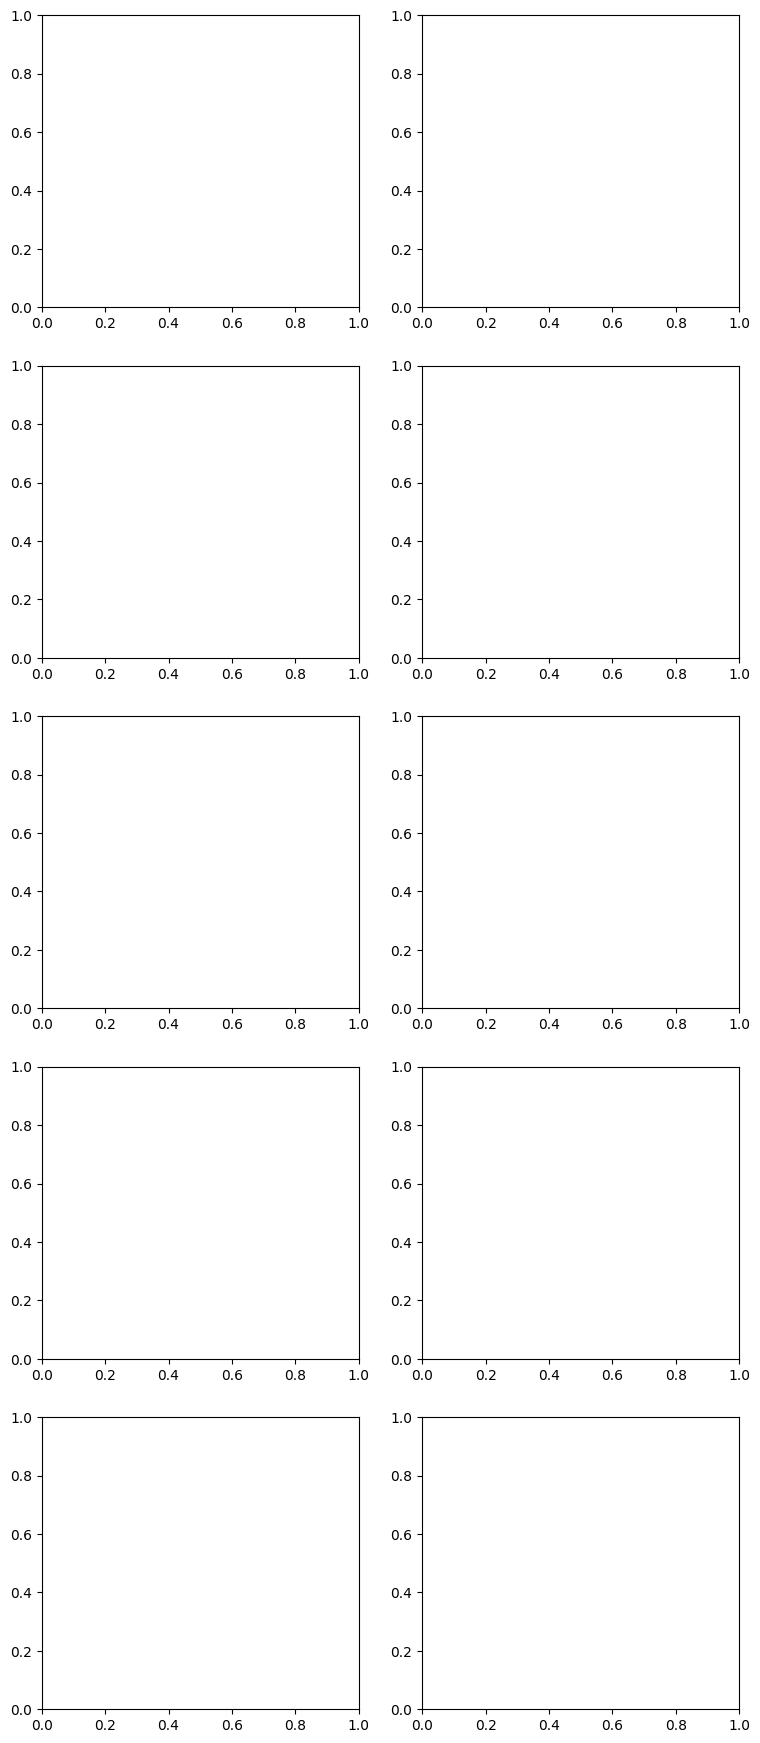

In [14]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(5, 2, figsize=(9, 22))

for i, class_name in enumerate(SELECTED_CLASSES):
    axes[i, 0].imshow(baseline_images[i])
    axes[i, 0].set_title(f"Base model — {class_name}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(refined_images[i])
    axes[i, 1].set_title(f"LoRA refined — {class_name}")
    axes[i, 1].axis("off")

plt.suptitle(
    "Stable Diffusion v1.5: Before vs Oxford-102 LoRA Refinement",
    fontsize=15
)
plt.tight_layout()
plt.show()


## 16. Generate a custom flower prompt

Change `CUSTOM_PROMPT` to test the refined model with another flower-related description.


  0%|          | 0/30 [00:00<?, ?it/s]

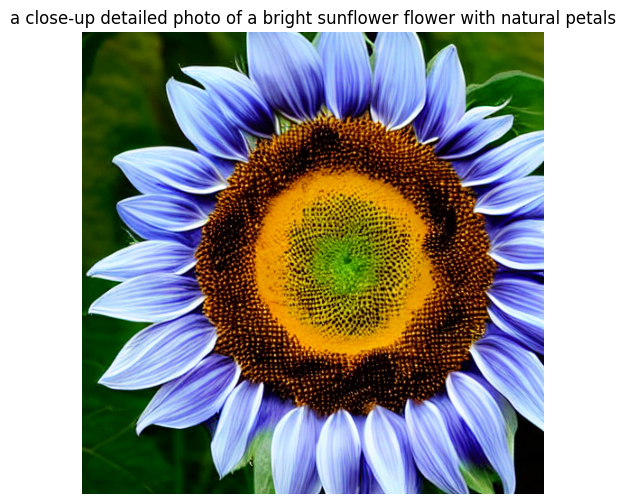

Saved: /content/task1_oxford102_lora/task1_custom_refined_flower.png


In [15]:
CUSTOM_PROMPT = "a close-up detailed photo of a bright sunflower flower with natural petals"

generator = torch.Generator(device="cuda").manual_seed(123)
custom_image = refined_pipe(
    CUSTOM_PROMPT,
    num_inference_steps=30,
    guidance_scale=7.5,
    generator=generator
).images[0]

custom_path = ROOT / "task1_custom_refined_flower.png"
custom_image.save(custom_path)

plt.figure(figsize=(6, 6))
plt.imshow(custom_image)
plt.title(CUSTOM_PROMPT)
plt.axis("off")
plt.show()

print("Saved:", custom_path)


In [18]:
import pandas as pd
import json
from pathlib import Path

ROOT = Path("/content/task1_oxford102_lora")
TRAIN_DIR = ROOT / "flower_lora_dataset"

# Reload metadata created earlier
metadata_path = TRAIN_DIR / "metadata.jsonl"

records = []
with open(metadata_path, "r") as f:
    for line in f:
        records.append(json.loads(line))

train_df = pd.DataFrame(records)

print("✅ train_df restored")
print("Shape:", train_df.shape)
display(train_df.head())


✅ train_df restored
Shape: (150, 2)


,file_name,text
0,daffodil_05733.jpg,a detailed photo of a daffodil flower
1,daffodil_05713.jpg,a detailed photo of a daffodil flower
2,daffodil_05721.jpg,a detailed photo of a daffodil flower
3,daffodil_05701.jpg,a detailed photo of a daffodil flower
4,daffodil_05708.jpg,a detailed photo of a daffodil flower


## 17. Experiment record


In [19]:
import pandas as pd
experiment = pd.DataFrame([{
    "task": "Task 1 - Pre-trained text-to-image refinement",
    "dataset": "Oxford-102 Flowers",
    "selected_classes": ", ".join(SELECTED_CLASSES),
    "training_images": len(train_df),
    "base_model": MODEL_NAME,
    "method": "LoRA fine-tuning",
    "resolution": "512x512",
    "lora_rank": LORA_RANK,
    "learning_rate": LEARNING_RATE,
    "max_train_steps": MAX_TRAIN_STEPS,
    "evaluation": "Base vs LoRA-refined generation with identical prompts/seeds"
}])

display(experiment)

experiment_path = ROOT / "task1_experiment_summary.csv"
experiment.to_csv(experiment_path, index=False)
print("Saved:", experiment_path)


,task,dataset,selected_classes,training_images,base_model,method,resolution,lora_rank,learning_rate,max_train_steps,evaluation
0,Task 1 - Pre-trained text-to-image refinement,Oxford-102 Flowers,"daffodil, sunflower, rose, lotus, hibiscus",150,stable-diffusion-v1-5/stable-diffusion-v1-5,LoRA fine-tuning,512x512,4,0.0001,300,Base vs LoRA-refined generation with identical...


Saved: /content/task1_oxford102_lora/task1_experiment_summary.csv


In [21]:
from pathlib import Path
from PIL import Image

ROOT = Path("/content/task1_oxford102_lora")

SELECTED_CLASSES = [
    "daffodil",
    "sunflower",
    "rose",
    "lotus",
    "hibiscus"
]

# Find the baseline image directory
possible_dirs = [
    ROOT / "baseline_images",
    ROOT / "base_images",
]

BASELINE_DIR = None

for folder in possible_dirs:
    if folder.exists():
        BASELINE_DIR = folder
        break

if BASELINE_DIR is None:
    print("❌ Baseline image folder not found.")
else:
    baseline_files = sorted(BASELINE_DIR.glob("*.png"))

    baseline_images = [
        Image.open(file).convert("RGB")
        for file in baseline_files
    ]

    print("✅ baseline_images restored")
    print("Directory:", BASELINE_DIR)
    print("Images found:", len(baseline_images))

    for file in baseline_files:
        print("-", file.name)

✅ baseline_images restored
Directory: /content/task1_oxford102_lora/baseline_images
Images found: 5
- baseline_0_daffodil.png
- baseline_1_sunflower.png
- baseline_2_rose.png
- baseline_3_lotus.png
- baseline_4_hibiscus.png


## 18. Task 1 Summary and Conclusion

This task demonstrates domain adaptation of a **pre-trained text-to-image diffusion model**. Stable Diffusion v1.5 provides the pre-trained visual and language-conditioned generation capability, while LoRA introduces a small number of trainable parameters that are optimized on the custom Oxford-102 flower subset.

The experiment therefore differs from Tasks 2 and 5: those tasks trained GAN-based generators, while Task 1 starts from an already pre-trained text-to-image model and **refines it for the flower domain**.


In [22]:
print("===== TASK 1 SUMMARY =====")
print("Dataset: Oxford-102 Flowers")
print("Base text-to-image model:", MODEL_NAME)
print("Refinement method: LoRA")
print("Selected categories:", ", ".join(SELECTED_CLASSES))
print("Training images:", len(train_df))
print("Training resolution: 512x512")
print("LoRA rank:", LORA_RANK)
print("Maximum optimization steps:", MAX_TRAIN_STEPS)
print("Generated baseline images:", len(baseline_images))
print("Generated refined images:", len(refined_images))
print("LoRA weight files:", ", ".join(p.name for p in weight_files))

print(
    "\nConclusion: A pre-trained Stable Diffusion model was successfully "
    "refined using LoRA on a custom subset of the Oxford-102 Flowers dataset. "
    "The original model weights were retained while lightweight adapter "
    "parameters learned flower-domain information. Identical text prompts "
    "were generated before and after refinement to provide a qualitative "
    "comparison of the domain-adapted model."
)


===== TASK 1 SUMMARY =====
Dataset: Oxford-102 Flowers
Base text-to-image model: stable-diffusion-v1-5/stable-diffusion-v1-5
Refinement method: LoRA
Selected categories: daffodil, sunflower, rose, lotus, hibiscus
Training images: 150
Training resolution: 512x512
LoRA rank: 4
Maximum optimization steps: 300
Generated baseline images: 5
Generated refined images: 5
LoRA weight files: pytorch_lora_weights.safetensors

Conclusion: A pre-trained Stable Diffusion model was successfully refined using LoRA on a custom subset of the Oxford-102 Flowers dataset. The original model weights were retained while lightweight adapter parameters learned flower-domain information. Identical text prompts were generated before and after refinement to provide a qualitative comparison of the domain-adapted model.


## 19. Files to keep for final submission

After the notebook runs successfully, keep:

- The **executed Task 1 `.ipynb` notebook** with all outputs visible
- The LoRA `.safetensors` weight file from `sd15_oxford102_lora/`
- `task1_experiment_summary.csv`
- Baseline flower images
- Refined flower images
- `task1_custom_refined_flower.png`

For GitHub, the notebook, README explanation, experiment summary, and representative before/after images are the most useful. The LoRA weights can be included if repository/file-size limits allow it.

### Note on evaluation
Fine-tuning diffusion models can overfit, especially on small datasets. The generated images should therefore be presented as an experimental qualitative result, not as proof that the refined model is universally better than the original model.
